In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

prediction_data = pd.read_csv('market_data_with_weather.csv')
# Convert the date column to datetime objects
prediction_data['date'] = pd.to_datetime(prediction_data['date'])

print(prediction_data.head())
print(prediction_data.shape)
prediction_data.columns.tolist()

        date market      commodity unit  longitude  latitude   price  \
0 2008-07-15  Owino      Plantains   Kg      32.57      0.32  266.25   
1 2008-08-15  Owino      Plantains   Kg      32.57      0.32  310.00   
2 2008-09-15  Owino  Cassava Flour   Kg      32.57      0.32  744.44   
3 2008-09-15  Owino      Plantains   Kg      32.57      0.32  351.11   
4 2008-10-15  Owino  Cassava Flour   Kg      32.57      0.32  710.00   

  pricetype  market_id  crop_id  forecastable  rainfall_mm  temp_mean_c  \
0    Retail         35       15         False          NaN          NaN   
1    Retail         35       15         False          NaN          NaN   
2    Retail         35        3          True        55.18     21.99625   
3    Retail         35       15         False        55.18     21.99625   
4    Retail         35        3          True       113.67     21.83871   

   demand_index  
0      2.206417  
1      1.895518  
2      1.186680  
3      1.673986  
4      1.244230  
(21107, 

['date',
 'market',
 'commodity',
 'unit',
 'longitude',
 'latitude',
 'price',
 'pricetype',
 'market_id',
 'crop_id',
 'forecastable',
 'rainfall_mm',
 'temp_mean_c',
 'demand_index']

Model

# 1. DATA PREPARATION & FEATURE ENGINEERING

In [ ]:
# Filter exclusively for forecastable data
price_ml = prediction_data[prediction_data['forecastable'] == True].copy()
price_ml = price_ml.sort_values(by=['market', 'commodity', 'date'])

# Generate 1, 2, 3, and 12-month (yearly seasonality) lag features
for lag in [1, 2, 3, 12]:
    price_ml[f'price_lag_{lag}'] = price_ml.groupby(['market', 'commodity'])['price'].shift(lag)
    price_ml[f'rainfall_lag_{lag}'] = price_ml.groupby(['market', 'commodity'])['rainfall_mm'].shift(lag)

# Extract Seasonality & Target Variables
price_ml['month'] = price_ml['date'].dt.month
price_ml['year'] = price_ml['date'].dt.year
price_ml['next_month_price'] = price_ml.groupby(['market', 'commodity'])['price'].shift(-1)

# Drop rows with NaN values resulting from the lag shifts
lag_cols = [f'price_lag_{i}' for i in [1, 2, 3, 12]] + [f'rainfall_lag_{i}' for i in [1, 2, 3, 12]]
price_ml = price_ml.dropna(subset=lag_cols + ['next_month_price'])

print(f"Data shape after feature engineering: {price_ml.shape}")
print(price_ml.head())


Data shape after feature engineering: (3943, 25)
          date  market commodity unit  longitude  latitude   price pricetype  \
825 2012-04-15  Iganga     Beans   Kg      33.47      0.61  1992.0    Retail   
866 2012-05-15  Iganga     Beans   Kg      33.47      0.61  2150.0    Retail   
907 2012-06-15  Iganga     Beans   Kg      33.47      0.61  2217.0    Retail   
948 2012-07-15  Iganga     Beans   Kg      33.47      0.61  1842.0    Retail   
990 2012-08-15  Iganga     Beans   Kg      33.47      0.61  1700.0    Retail   

     market_id  crop_id  ...  rainfall_lag_1  price_lag_2  rainfall_lag_2  \
825          8        1  ...           54.12       1834.0           21.50   
866          8        1  ...          273.11       1950.0           54.12   
907          8        1  ...          165.16       1992.0          273.11   
948          8        1  ...          122.91       2150.0          165.16   
990          8        1  ...           62.48       2217.0          122.91   

     pr

# 2. FEATURE SELECTION & CHRONOLOGICAL SPLIT

In [ ]:
from sklearn.preprocessing import StandardScaler
features = [
    'market_encoded',
    'crop_encoded',
    'month',
    'rainfall_mm',
    'temp_mean_c',
    'demand_index',
    'price_lag_1',
    'price_lag_2',
    'price_lag_3',
    'price_lag_12',
    'rainfall_lag_1',
    'rainfall_lag_2',
    'rainfall_lag_3',
    'rainfall_lag_12'
]

# Chronological split (80% train, 20% test per series)
train_parts, test_parts = [], []
for (mkt, crop), group in price_ml.groupby(['market', 'commodity']):
    group = group.sort_values('date')
    split_point = int(len(group) * 0.8)
    train_parts.append(group.iloc[:split_point])
    test_parts.append(group.iloc[split_point:])

train_df = pd.concat(train_parts).sort_values(['market', 'commodity', 'date'])
test_df = pd.concat(test_parts).sort_values(['market', 'commodity', 'date'])

# Target encoding
overall_train_mean = train_df['price'].mean()
market_means = train_df.groupby('market')['price'].mean()
crop_means = train_df.groupby('commodity')['price'].mean()

for df in [train_df, test_df, price_ml]:
    df['market_encoded'] = df['market'].map(market_means).fillna(overall_train_mean)
    df['crop_encoded'] = df['commodity'].map(crop_means).fillna(overall_train_mean)

X_train = train_df[features]
y_train = train_df['next_month_price']
X_test = test_df[features]
y_test = test_df['next_month_price']

# Feature scaling required for Linear Regression & ElasticNet
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set size: {len(train_df)} rows")
print(f"Testing set size: {len(test_df)} rows")

Training set size: 3142 rows
Testing set size: 801 rows


# 3. MULTI-MODEL TRAINING (Random Forest Regressor, XGBoost, Linear regession, Elastic Net)


In [ ]:

from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression, ElasticNet

# Define model dictionary with appropriate feature matrices
models = {
    "Random Forest": (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), X_train, X_test),
    "XGBoost": (XGBRegressor(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42, n_jobs=-1), X_train, X_test),
    "Linear Regression": (LinearRegression(), X_train_scaled, X_test_scaled),
    "ElasticNet": (ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42), X_train_scaled, X_test_scaled)
}

# Dictionary to store predictions for evaluation in the next cell
predictions = {}

# Train each model and store test set predictions
print("Training models...")
for name, (model_obj, x_tr, x_te) in models.items():
    model_obj.fit(x_tr, y_train)
    predictions[name] = model_obj.predict(x_te)
    print(f"✓ {name} trained successfully.")


Training models...
✓ Random Forest trained successfully.
✓ XGBoost trained successfully.
✓ Linear Regression trained successfully.
✓ ElasticNet trained successfully.


# 4. EVALUATION


In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_absolute_percentage_error, r2_score
import pandas as pd

results = []

# 1. Naive Baseline Persistence Calculation
baseline_pred = test_df['price']
results.append({
    'Model': 'Naive Baseline',
    'MAE (UGX)': mean_absolute_error(y_test, baseline_pred),
    'RMSE (UGX)': root_mean_squared_error(y_test, baseline_pred),
    'MAPE (%)': mean_absolute_percentage_error(y_test, baseline_pred) * 100,
    'R² Score': r2_score(y_test, baseline_pred)
})

for name, preds in predictions.items():
    results.append({
        'Model': name,
        'MAE (UGX)': mean_absolute_error(y_test, preds),
        'RMSE (UGX)': root_mean_squared_error(y_test, preds),
        'MAPE (%)': mean_absolute_percentage_error(y_test, preds) * 100,
        'R² Score': r2_score(y_test, preds)
    })

# 3. Display Overall Comparison Table
results_df = pd.DataFrame(results)
print("=== Overall Model Performance Comparison ===")
print(results_df.to_string(index=False))


=== Overall Model Performance Comparison ===
            Model  MAE (UGX)  RMSE (UGX)  MAPE (%)  R² Score
   Naive Baseline 193.207241  338.039280  8.090931  0.905231
    Random Forest 256.755562  381.082101 10.951185  0.879560
          XGBoost 236.022393  358.654109  9.915005  0.893319
Linear Regression 273.015390  404.471623 11.210734  0.864322
       ElasticNet 276.740511  406.404305 11.442027  0.863022


## Linear Relationship Chart: Regplot (Scatter + Fit Line)
This chart plots price_lag_1 vs. next_month_price. It displays a strong, direct linear trend line where as last month's price increases, next month's price increases proportionally.

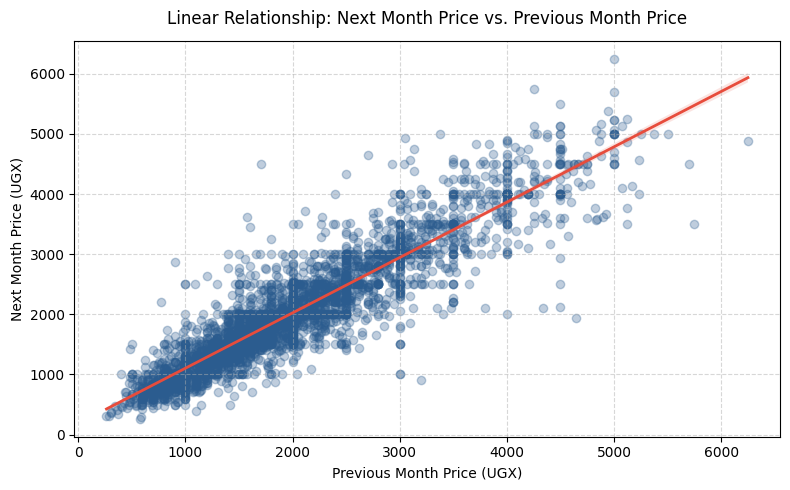

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.regplot(
    data=price_ml,
    x='price_lag_1',
    y='next_month_price',
    scatter_kws={'alpha': 0.3, 'color': '#2b5c8f'},
    line_kws={'color': '#e74c3c', 'linewidth': 2},
)

plt.title(
    'Linear Relationship: Next Month Price vs. Previous Month Price',
    fontsize=12,
    pad=12,
)
plt.xlabel('Previous Month Price (UGX)', fontsize=10)
plt.ylabel('Next Month Price (UGX)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## 4b: BASELINE COMPARISON PER PAIR


In [ ]:
best_model_name = (
    results_df[results_df['Model'] != 'Naive Baseline']
    .sort_values('MAPE (%)')
    .iloc[0]['Model']
)
print(f"Evidence-based best model: {best_model_name}")
selected_preds = predictions[best_model_name]

model_pred_series = pd.Series(selected_preds, index=test_df.index)
baseline_comparison_rows = []

for (mkt, crop), group in test_df.groupby(['market', 'commodity']):
    idx = group.index
    actual = y_test.loc[idx]
    b_mape = mean_absolute_percentage_error(actual, group['price'])
    m_mape = mean_absolute_percentage_error(actual, model_pred_series.loc[idx])

    baseline_comparison_rows.append({
        'market': mkt,
        'commodity': crop,
        'baseline_mape': round(b_mape, 4),
        'model_mape': round(m_mape, 4),
        'model_beats_baseline': m_mape < b_mape,
    })

baseline_comparison_df = pd.DataFrame(baseline_comparison_rows)
print(f"=== {best_model_name} vs. Baseline, per Market-Crop Pair ===")
print(baseline_comparison_df.to_string(index=False))

n_wins = baseline_comparison_df['model_beats_baseline'].sum()
print(f"\nPairs where {best_model_name} beats the naive baseline: {n_wins} / {len(baseline_comparison_df)}")

Evidence-based best model: XGBoost
=== XGBoost vs. Baseline, per Market-Crop Pair ===
 market     commodity  baseline_mape  model_mape  model_beats_baseline
 Iganga         Beans         0.0753      0.0834                 False
 Iganga Cassava Flour         0.0892      0.1223                 False
 Iganga Maize (White)         0.1530      0.1705                 False
 Iganga   Maize Flour         0.0639      0.0807                 False
 Iganga        Millet         0.0811      0.0769                  True
 Iganga       Sorghum         0.1120      0.1285                 False
  Jinja         Beans         0.0537      0.0728                 False
  Jinja Cassava Flour         0.0389      0.0508                 False
  Jinja Maize (White)         0.0492      0.0708                 False
  Jinja   Maize Flour         0.0499      0.0672                 False
  Jinja        Millet         0.0741      0.0967                 False
  Jinja       Sorghum         0.0861      0.0629              

## 4c. Final Predictions -- Model or Baseline, Whichever Wins

Per the project's methodology: keep the model's prediction only where it actually beats the baseline for that specific market-crop pair; fall back to the baseline everywhere else.

**This cell was previously empty.** The logic below builds `final_predictions`: it starts from the chosen model's predictions, then overwrites each losing pair's predictions with the baseline instead, using the per-pair result from Cell 13.

In [ ]:
final_predictions = model_pred_series.copy()

for _, row in baseline_comparison_df.iterrows():
    if not row['model_beats_baseline']:
        idx = test_df[
            (test_df['market'] == row['market']) & (test_df['commodity'] == row['commodity'])
        ].index
        final_predictions.loc[idx] = test_df.loc[idx, 'price']

final_mape = mean_absolute_percentage_error(y_test, final_predictions)
pure_model_mape = mean_absolute_percentage_error(y_test, model_pred_series)
pure_baseline_mape = mean_absolute_percentage_error(y_test, test_df['price'])

print(f"Pure {best_model_name} MAPE:      {pure_model_mape * 100:.2f}%")
print(f"Pure naive baseline MAPE:  {pure_baseline_mape * 100:.2f}%")
print(f"Final blended MAPE:        {final_mape * 100:.2f}%  (model where it wins, baseline elsewhere)")


Pure XGBoost MAPE:      9.92%
Pure naive baseline MAPE:  8.09%
Final blended MAPE:        7.91%  (model where it wins, baseline elsewhere)


##LOOKUP BASELINE ENCODINGS

In [ ]:
## 5. LOOKUP BASELINE ENCODINGS

print("=== Crop Baseline Encodings (training-set average price) ===")
for crop_name, mean_price in crop_means.items():
    print(f"{crop_name} -> Baseline: {mean_price:.2f} UGX")

print("\n=== Market Baseline Encodings (training-set average price) ===")
for market_name, mean_price in market_means.items():
    print(f"{market_name} -> Baseline: {mean_price:.2f} UGX")

=== Crop Baseline Encodings (training-set average price) ===
Beans -> Baseline: 2652.96 UGX
Cassava Flour -> Baseline: 1486.54 UGX
Maize (White) -> Baseline: 1182.18 UGX
Maize Flour -> Baseline: 2011.84 UGX
Millet -> Baseline: 2220.66 UGX
Sorghum -> Baseline: 1577.23 UGX

=== Market Baseline Encodings (training-set average price) ===
Iganga -> Baseline: 1699.71 UGX
Jinja -> Baseline: 1988.10 UGX
Lira -> Baseline: 1628.72 UGX
Mbarara -> Baseline: 2166.85 UGX
Owino -> Baseline: 1884.65 UGX


# 5. FEATURE IMPORTANCE (What drives price changes?)


In [ ]:
importance_model_name = best_model_name if best_model_name in ('Random Forest', 'XGBoost') else 'XGBoost'
if importance_model_name != best_model_name:
    print(f"Note: {best_model_name} was the best overall model, but feature importance "
          f"is only meaningful for tree models -- showing {importance_model_name} instead.")
tree_model = models[importance_model_name][0]

importances = pd.DataFrame({
    'Feature': features,
    'Importance': tree_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\n=== Feature Importance ===")
print(importances.to_string(index=False))



=== Feature Importance ===
        Feature  Importance
    price_lag_1    0.778560
    price_lag_2    0.063546
   demand_index    0.027004
    price_lag_3    0.023703
   crop_encoded    0.023632
   price_lag_12    0.013326
          month    0.012329
 rainfall_lag_2    0.010603
 rainfall_lag_1    0.008601
 rainfall_lag_3    0.008331
 market_encoded    0.008105
rainfall_lag_12    0.008049
    temp_mean_c    0.007151
    rainfall_mm    0.007060


## Future prediction cell

For testing the model's forecasting behaviour on a future date.


In [ ]:
target_market = 'Owino'
target_crop = 'Beans'
target_month = 7
target_year = 2026

# Filter data for the specific market & commodity
group_data = price_ml[
    (price_ml['market'] == target_market)
    & (price_ml['commodity'] == target_crop)
].sort_values('date')

# Look up encoded values automatically using fitted means
target_market_enc = market_means.get(target_market, overall_train_mean)
target_crop_enc = crop_means.get(target_crop, overall_train_mean)

# Construct feature dictionary for inference
sample_features = {
    'market_encoded': target_market_enc,
    'crop_encoded': target_crop_enc,
    'month': target_month,
    'rainfall_mm': 85.0,
    'temp_mean_c': 22.5,
    'demand_index': group_data['demand_index'].iloc[-1],
    'price_lag_1': group_data['price'].iloc[-1],
    'price_lag_2': group_data['price'].iloc[-2],
    'price_lag_3': group_data['price'].iloc[-3],
    'price_lag_12': group_data['price'].iloc[-12],
    'rainfall_lag_1': group_data['rainfall_mm'].iloc[-1],
    'rainfall_lag_2': group_data['rainfall_mm'].iloc[-2],
    'rainfall_lag_3': group_data['rainfall_mm'].iloc[-3],
    'rainfall_lag_12': group_data['rainfall_mm'].iloc[-12],
}

# Convert sample features into DataFrame aligned with training features
sample_df = pd.DataFrame([sample_features])[features]

SCALED_MODELS = ('Linear Regression', 'ElasticNet')
if best_model_name in SCALED_MODELS:
    sample_input = scaler.transform(sample_df)
else:
    sample_input = sample_df

chosen_model = models[best_model_name][0]
predicted_price = chosen_model.predict(sample_input)[0]

print(f'=== Dynamic Price Prediction ({target_market} - {target_crop}) ===')
print(
    f'Predicted Price for Month {target_month}/{target_year}:'
    f' {predicted_price:.2f} UGX'
)

=== Dynamic Price Prediction (Owino - Beans) ===
Predicted Price for Month 7/2026: 4475.15 UGX


## 7. MARKET ADVISORY: BEST MONTH TO SELL

### This mainly for analysis reasons



In [ ]:

def get_best_selling_months(df):
    print("=== Agricultural Market Advisory: Best Months to Sell ===")

    # Group by market, crop, and month to find historical average prices
    monthly_averages = df.groupby(['market', 'commodity', 'month'])['price'].mean().reset_index()

    best_months = monthly_averages.loc[monthly_averages.groupby(['market', 'commodity'])['price'].idxmax()]

    best_months = best_months.sort_values(by=['market', 'commodity'])

    import calendar
    best_months['month_name'] = best_months['month'].apply(lambda x: calendar.month_name[x])

    for _, row in best_months.iterrows():
        print(f" Market: {row['market']:<10} | Crop: {row['commodity']:<15} | Best Month: {row['month_name']:<10} | Avg Price: {row['price']:.2f} UGX")

get_best_selling_months(price_ml)

=== Agricultural Market Advisory: Best Months to Sell ===
 Market: Iganga     | Crop: Beans           | Best Month: May        | Avg Price: 3206.65 UGX
 Market: Iganga     | Crop: Cassava Flour   | Best Month: December   | Avg Price: 1480.45 UGX
 Market: Iganga     | Crop: Maize (White)   | Best Month: June       | Avg Price: 1231.33 UGX
 Market: Iganga     | Crop: Maize Flour     | Best Month: July       | Avg Price: 2091.95 UGX
 Market: Iganga     | Crop: Millet          | Best Month: March      | Avg Price: 2169.36 UGX
 Market: Iganga     | Crop: Sorghum         | Best Month: March      | Avg Price: 1622.90 UGX
 Market: Jinja      | Crop: Beans           | Best Month: May        | Avg Price: 3799.58 UGX
 Market: Jinja      | Crop: Cassava Flour   | Best Month: December   | Avg Price: 1502.86 UGX
 Market: Jinja      | Crop: Maize (White)   | Best Month: May        | Avg Price: 1568.47 UGX
 Market: Jinja      | Crop: Maize Flour     | Best Month: July       | Avg Price: 2269.38 UGX
 M